In [ ]:
import torch
import torchvision
import scipy

In [ ]:
from torchvision.datasets import Flowers102

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
torch.__version__

'2.14.1+cu130'

In [ ]:
torchvision.__version__

'0.29.1+cu130'

In [ ]:
scipy.__version__

'1.16.3'

In [ ]:
training_dataset = Flowers102(root="data",
                     split="train",
                     download=True)

100%|██████████| 345M/345M [00:13<00:00, 25.8MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.55MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 21.3MB/s]


In [ ]:
len(training_dataset)

1020

In [ ]:
testing_dataset = Flowers102(root="data",
                             split="test",
                             download=True)

In [ ]:
len(testing_dataset)

6149

In [ ]:
val_dataset = Flowers102(
    root= "data",
    split= "val",
    download=True
)

In [ ]:
len(val_dataset)

1020

In [ ]:
training_dataset[0]

(<PIL.Image.Image image mode=RGB size=754x500>, 0)

In [ ]:
sample = training_dataset[0]

In [ ]:
print(len(sample))
print(type(sample))

2
<class 'tuple'>


In [ ]:
image, label = training_dataset[0]

print("Image type:", type(image))
print("Label:", label)
print("Image size:", image.size)

Image type: <class 'PIL.Image.Image'>
Label: 0
Image size: (754, 500)


In [ ]:
selected_flowers = {
    "Siam tulip": 38,
    "Oxeye daisy": 48,
    "Rose": 73,
    "Sunflower": 53,
    "Dandelion": 49
}

In [ ]:
training_dataset.classes

['pink primrose',
 'hard-leaved pocket orchid',
 'canterbury bells',
 'sweet pea',
 'english marigold',
 'tiger lily',
 'moon orchid',
 'bird of paradise',
 'monkshood',
 'globe thistle',
 'snapdragon',
 "colt's foot",
 'king protea',
 'spear thistle',
 'yellow iris',
 'globe-flower',
 'purple coneflower',
 'peruvian lily',
 'balloon flower',
 'giant white arum lily',
 'fire lily',
 'pincushion flower',
 'fritillary',
 'red ginger',
 'grape hyacinth',
 'corn poppy',
 'prince of wales feathers',
 'stemless gentian',
 'artichoke',
 'sweet william',
 'carnation',
 'garden phlox',
 'love in the mist',
 'mexican aster',
 'alpine sea holly',
 'ruby-lipped cattleya',
 'cape flower',
 'great masterwort',
 'siam tulip',
 'lenten rose',
 'barbeton daisy',
 'daffodil',
 'sword lily',
 'poinsettia',
 'bolero deep blue',
 'wallflower',
 'marigold',
 'buttercup',
 'oxeye daisy',
 'common dandelion',
 'petunia',
 'wild pansy',
 'primula',
 'sunflower',
 'pelargonium',
 'bishop of llandaff',
 'gaura',

In [ ]:
from collections import Counter

In [ ]:
label_counts = Counter(val_dataset._labels)

In [ ]:
print(label_counts)

Counter({0: 10, 1: 10, 2: 10, 3: 10, 4: 10, 5: 10, 6: 10, 7: 10, 8: 10, 9: 10, 10: 10, 11: 10, 12: 10, 13: 10, 14: 10, 15: 10, 20: 10, 16: 10, 17: 10, 18: 10, 19: 10, 21: 10, 22: 10, 23: 10, 24: 10, 25: 10, 26: 10, 27: 10, 28: 10, 29: 10, 30: 10, 31: 10, 32: 10, 33: 10, 34: 10, 35: 10, 36: 10, 37: 10, 38: 10, 39: 10, 40: 10, 41: 10, 42: 10, 43: 10, 44: 10, 45: 10, 46: 10, 47: 10, 48: 10, 49: 10, 50: 10, 51: 10, 52: 10, 53: 10, 54: 10, 55: 10, 56: 10, 57: 10, 58: 10, 59: 10, 60: 10, 61: 10, 62: 10, 63: 10, 64: 10, 65: 10, 66: 10, 67: 10, 68: 10, 69: 10, 70: 10, 71: 10, 72: 10, 73: 10, 74: 10, 75: 10, 76: 10, 77: 10, 78: 10, 79: 10, 80: 10, 81: 10, 82: 10, 83: 10, 84: 10, 85: 10, 86: 10, 87: 10, 88: 10, 89: 10, 90: 10, 91: 10, 92: 10, 93: 10, 94: 10, 95: 10, 96: 10, 97: 10, 98: 10, 99: 10, 100: 10, 101: 10})


In [ ]:
for flower, label in selected_flowers.items():
  print(flower, label_counts[label])

Siam tulip 10
Oxeye daisy 10
Rose 10
Sunflower 10
Dandelion 10


In [ ]:
from torch.utils.data import Subset

In [ ]:
selected_labels = list(selected_flowers.values())

In [ ]:
selected_labels

[38, 48, 73, 53, 49]

In [ ]:
train_indices = []
test_indices = []
val_indices = []

for i, label in enumerate(training_dataset._labels):
  if label in selected_labels:
    train_indices.append(i)

for i, label in enumerate(testing_dataset._labels):
  if label in selected_labels:
    test_indices.append(i)

for i, label in enumerate(val_dataset._labels):
  if label in selected_labels:
    val_indices.append(i)

In [ ]:
train_subset = Subset(training_dataset,train_indices)


In [ ]:
print("selected traning images: ", len(train_subset))

selected traning images:  50


In [ ]:
test_subset = Subset(testing_dataset, test_indices)
val_subset = Subset(val_dataset, val_indices)

In [ ]:
print("selected test images: ", len(test_subset))

selected test images:  314


In [ ]:
print("selected val images: ", len(val_subset))

selected val images:  50


In [ ]:
from torchvision import transforms

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
image, label = train_subset[0]
transfomed_image = transform(image)

In [ ]:
print("orignal image: ", image.size)
print("transform image: ", transfomed_image.shape)
print("image data type: ", transfomed_image.dtype)

orignal image:  (500, 500)
transform image:  torch.Size([3, 224, 224])
image data type:  torch.float32


In [ ]:
label_mapping = {
    38: 0,
    48: 1,
    73: 2,
    53: 3,
    49: 4
}

In [ ]:
from torch.utils.data import Dataset

In [ ]:
class FlowerDataset(Dataset):

    def __init__(self, subset, transform, label_mapping):
        self.subset = subset
        self.transform = transform
        self.label_mapping = label_mapping

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]

        image = self.transform(image)

        label = self.label_mapping[label]

        return image, label

In [ ]:
train_data = FlowerDataset(train_subset, transform, label_mapping)

val_data = FlowerDataset(val_subset, transform, label_mapping)

test_data = FlowerDataset(test_subset, transform, label_mapping)

In [ ]:
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

Training: 50
Validation: 50
Testing: 314


In [ ]:
image, label = train_data[0]

print("Image shape:", image.shape)
print("New label:", label)

Image shape: torch.Size([3, 224, 224])
New label: 0


In [ ]:
from torch.utils.data import DataLoader

In [ ]:
BATCH_SIZE = 10

In [ ]:
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

Images shape: torch.Size([10, 3, 224, 224])
Labels shape: torch.Size([10])
Labels: tensor([0, 1, 2, 2, 4, 2, 3, 2, 1, 4])


In [51]:
import torch.nn as nn
from torchvision import models

In [52]:
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 75.6MB/s]


In [53]:
print(model.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [54]:
model.fc = nn.Linear(512,5)

In [55]:
model.fc

Linear(in_features=512, out_features=5, bias=True)

In [56]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [57]:
model = model.to(device)

In [59]:
criterion = nn.CrossEntropyLoss()


In [60]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [61]:
model.train()

for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    print("Images:", images.shape)
    print("Labels:", labels.shape)
    break

Images: torch.Size([10, 3, 224, 224])
Labels: torch.Size([10])


In [62]:
model.train()

for images, labels in train_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Step 1: Forward pass
    outputs = model(images)

    # Step 2: Calculate loss
    loss = criterion(outputs, labels)

    print("Predictions shape:", outputs.shape)
    print("Loss:", loss.item())

    break

Predictions shape: torch.Size([10, 5])
Loss: 2.0288655757904053


In [63]:
optimizer.zero_grad()

loss.backward()

optimizer.step()

In [64]:
model.train()

for images, labels in train_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Forward pass
    outputs = model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    print("Training loss:", loss.item())

    break

Training loss: 6.463746547698975


In [66]:
EPOCHS = 10

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {epoch_loss:.4f}")

Epoch [1/10], Loss: 1.2507
Epoch [2/10], Loss: 2.2447
Epoch [3/10], Loss: 1.4142
Epoch [4/10], Loss: 1.6442
Epoch [5/10], Loss: 1.6501
Epoch [6/10], Loss: 1.2974
Epoch [7/10], Loss: 1.5944
Epoch [8/10], Loss: 1.0779
Epoch [9/10], Loss: 0.9194
Epoch [10/10], Loss: 0.9101


In [67]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 56.00%


In [68]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

train_accuracy = 100 * correct / total

print(f"Training Accuracy: {train_accuracy:.2f}%")

Training Accuracy: 68.00%


In [69]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [70]:
# Apply augmentation to training images
train_data.transform = train_transform

# Keep validation and test images unchanged
val_data.transform = eval_transform
test_data.transform = eval_transform

In [71]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([10, 3, 224, 224])
Labels shape: torch.Size([10])


In [72]:
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

model.fc = nn.Linear(512, 5)

model = model.to(device)

In [73]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

In [74]:
EPOCHS = 10

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {epoch_loss:.4f}")

Epoch [1/10], Loss: 1.4079
Epoch [2/10], Loss: 0.4469
Epoch [3/10], Loss: 0.1987
Epoch [4/10], Loss: 0.1245
Epoch [5/10], Loss: 0.0876
Epoch [6/10], Loss: 0.0431
Epoch [7/10], Loss: 0.0490
Epoch [8/10], Loss: 0.0271
Epoch [9/10], Loss: 0.0166
Epoch [10/10], Loss: 0.0146


In [75]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 100.00%


In [76]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

train_accuracy = 100 * correct / total

print(f"Training Accuracy: {train_accuracy:.2f}%")

Training Accuracy: 100.00%


In [77]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

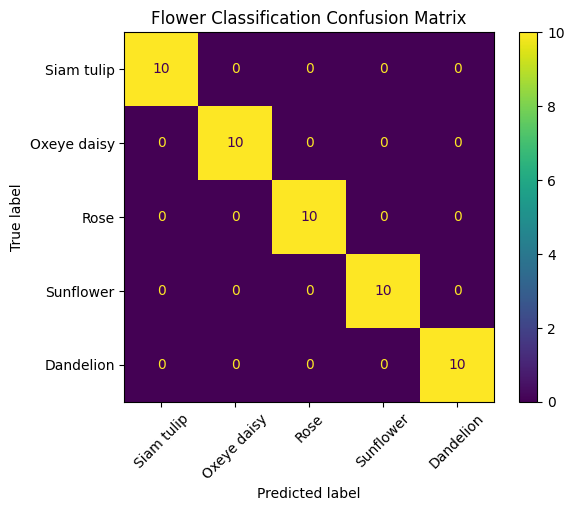

In [78]:
class_names = list(selected_flowers.keys())

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(xticks_rotation=45)
plt.title("Flower Classification Confusion Matrix")
plt.show()

In [79]:
model.eval()

test_correct = 0
test_total = 0
test_running_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Make predictions
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Get predicted classes
        predictions = outputs.argmax(dim=1)

        # Count correct predictions
        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

        test_running_loss += loss.item()

# Calculate final metrics
test_accuracy = 100 * test_correct / test_total
test_loss = test_running_loss / len(test_loader)

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Correct Predictions: {test_correct}/{test_total}")
print(f"Incorrect Predictions: {test_total - test_correct}/{test_total}")

Test Accuracy: 94.90%
Test Loss: 0.1400
Correct Predictions: 298/314
Incorrect Predictions: 16/314


In [80]:
from sklearn.metrics import classification_report

model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

class_names = list(selected_flowers.keys())

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

  Siam tulip       0.57      1.00      0.72        21
 Oxeye daisy       1.00      1.00      1.00        29
        Rose       1.00      0.89      0.94       151
   Sunflower       1.00      1.00      1.00        41
   Dandelion       1.00      1.00      1.00        72

    accuracy                           0.95       314
   macro avg       0.91      0.98      0.93       314
weighted avg       0.97      0.95      0.95       314



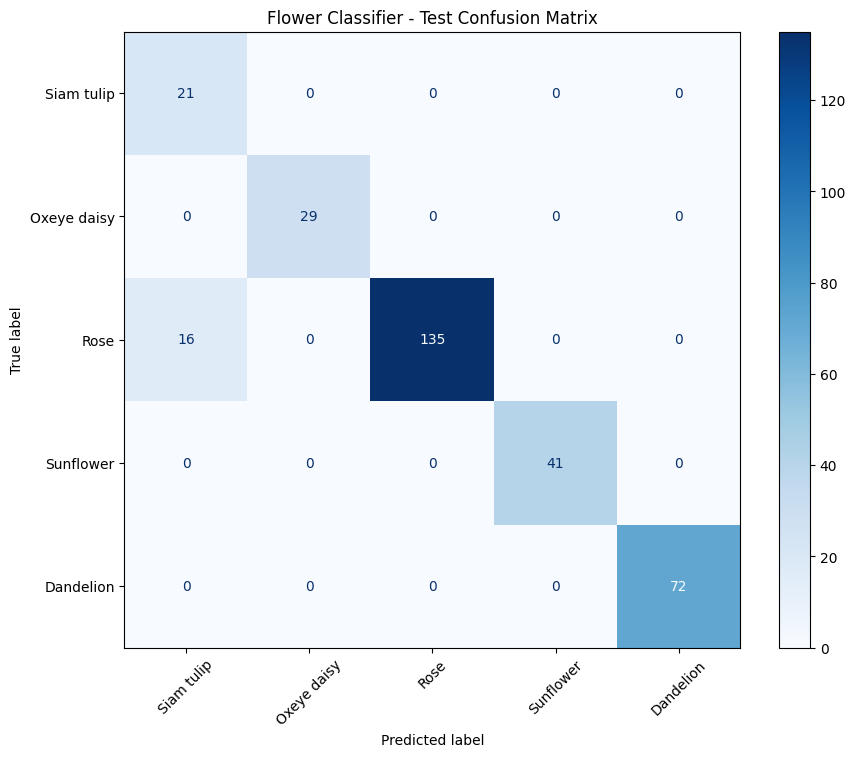

In [81]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Flower Classifier - Test Confusion Matrix")
plt.show()